In [ ]:

!pip install pandas numpy matplotlib seaborn plotly streamlit pyngrok -q



***Libraries Import***

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")


Saving Big_Mart_Sales.csv to Big_Mart_Sales.csv
Dataset uploaded successfully!


***STEP 5: Dataset Load***

In [ ]:
import io

file_name = 'Big_Mart_Sales.csv'

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

df.head()


Dataset Loaded Successfully!
Shape: (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


***PART 2 — LEVEL 1: DATA UNDERSTANDING***

***STEP 2: Dataset Information***

In [ ]:
# Dataset overview

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Number of Rows: 5681
Number of Columns: 11

Column Names:
['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5681 entries, 0 to 5680
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            5681 non-null   object 
 1   Item_Weight                4705 non-null   float64
 2   Item_Fat_Content           5681 non-null   object 
 3   Item_Visibility            5681 non-null   float64
 4   Item_Type                  5681 non-null   object 
 5   Item_MRP                   5681 non-null   float64
 6   Outlet_Identifier          5681 non-null   object 
 7   Outlet_Establishment_Year  5681 non-null   int64  
 8   Outlet_Size                4075 non-null   ob

***STEP 3: Missing Values Analysis***

In [ ]:

# Missing value analysis

missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_report = missing_report.sort_values(
    by='Missing Values',
    ascending=False
)

display(missing_report)


,Missing Values,Missing Percentage
Outlet_Size,1606,28.27
Item_Weight,976,17.18
Item_Identifier,0,0.00
Item_Fat_Content,0,0.00
Item_Visibility,0,0.00
Item_MRP,0,0.00
Item_Type,0,0.00
Outlet_Identifier,0,0.00
Outlet_Establishment_Year,0,0.00
Outlet_Location_Type,0,0.00


***Graph of Missing Values***

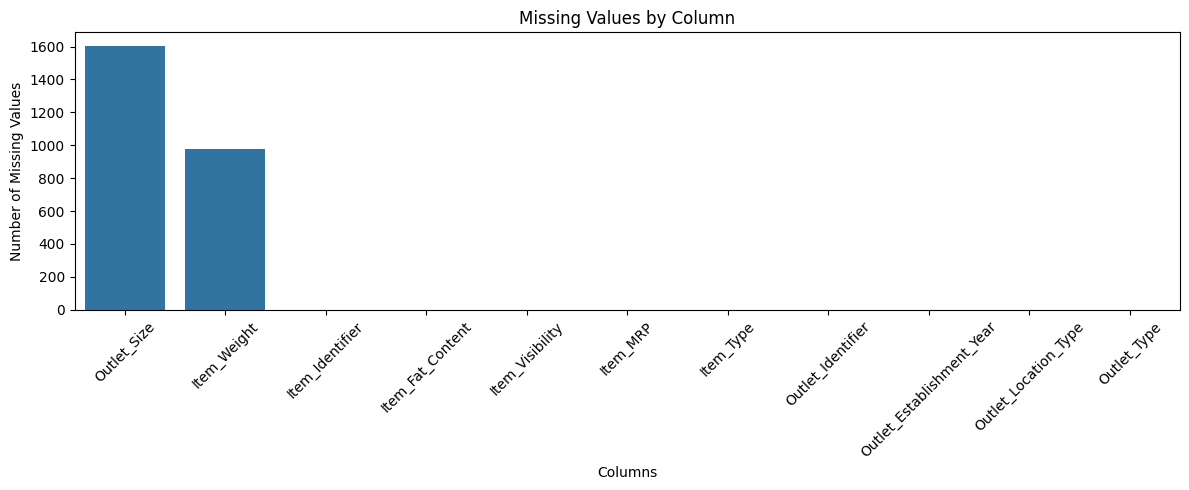

In [ ]:

plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing_report.index,
    y=missing_report['Missing Values']
)

plt.title('Missing Values by Column')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


***STEP 4: Duplicate Values Check***

In [ ]:

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)


Total Duplicate Records: 0


***STEP 5: Descriptive Statistics***

In [ ]:

# Numerical statistics

display(df.describe())

# Categorical statistics

display(df.describe(include='object'))


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year
count,4705.000000,5681.000000,5681.000000,5681.000000
mean,12.695633,0.065684,141.023273,1997.828903
std,4.664849,0.051252,61.809091,8.372256
min,4.555000,0.000000,31.990000,1985.000000
25%,8.645000,0.027047,94.412000,1987.000000
50%,12.500000,0.054154,141.415400,1999.000000
75%,16.700000,0.093463,186.026600,2004.000000
max,21.350000,0.323637,266.588400,2009.000000


,Item_Identifier,Item_Fat_Content,Item_Type,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type
count,5681,5681,5681,5681,4075,5681,5681
unique,1543,5,16,10,3,3,4
top,FDQ60,Low Fat,Snack Foods,OUT027,Medium,Tier 3,Supermarket Type1
freq,8,3396,789,624,1862,2233,3717


***STEP 6: Unique Values Analysis***

In [ ]:

for column in df.columns:

    print("\nColumn:", column)
    print("Unique Values:", df[column].nunique())

    if df[column].nunique() <= 20:
        print(df[column].value_counts(dropna=False))



Column: Item_Identifier
Unique Values: 1543

Column: Item_Weight
Unique Values: 410

Column: Item_Fat_Content
Unique Values: 5
Item_Fat_Content
Low Fat    3396
Regular    1935
LF          206
reg          78
low fat      66
Name: count, dtype: int64

Column: Item_Visibility
Unique Values: 5277

Column: Item_Type
Unique Values: 16
Item_Type
Snack Foods              789
Fruits and Vegetables    781
Household                638
Frozen Foods             570
Dairy                    454
Baking Goods             438
Canned                   435
Health and Hygiene       338
Meat                     311
Soft Drinks              281
Breads                   165
Hard Drinks              148
Starchy Foods            121
Others                   111
Breakfast                 76
Seafood                   25
Name: count, dtype: int64

Column: Item_MRP
Unique Values: 4402

Column: Outlet_Identifier
Unique Values: 10
Outlet_Identifier
OUT027    624
OUT013    621
OUT035    620
OUT049    620
OUT046    

***STEP 7: Level 1 Report***

In [ ]:

level1_report = {
    'Total Records': len(df),
    'Total Columns': len(df.columns),
    'Duplicate Records': df.duplicated().sum(),
    'Missing Item Weight': df['Item_Weight'].isnull().sum(),
    'Missing Outlet Size': df['Outlet_Size'].isnull().sum(),
    'Unique Products': df['Item_Identifier'].nunique(),
    'Unique Outlets': df['Outlet_Identifier'].nunique()
}

level1_df = pd.DataFrame(
    list(level1_report.items()),
    columns=['Metric', 'Value']
)

display(level1_df)

level1_df.to_csv('Level_1_Data_Understanding_Report.csv',
                 index=False)


,Metric,Value
0,Total Records,5681
1,Total Columns,11
2,Duplicate Records,0
3,Missing Item Weight,976
4,Missing Outlet Size,1606
5,Unique Products,1543
6,Unique Outlets,10


***PART 3 — LEVEL 2: DATA PREPARATION***

***STEP 8: Original Dataset***

In [ ]:

df_clean = df.copy()

print("Original Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)


Original Shape: (5681, 11)
Working Dataset Shape: (5681, 11)


***STEP 9: Item_Fat_Content Correct***

In [ ]:

df_clean['Item_Fat_Content'] = (
    df_clean['Item_Fat_Content']
    .astype(str)
    .str.strip()
    .str.lower()
)

df_clean['Item_Fat_Content'] = (
    df_clean['Item_Fat_Content'].replace({
        'lf': 'Low Fat',
        'low fat': 'Low Fat',
        'regular': 'Regular',
        'reg': 'Regular'
    })
)

print(df_clean['Item_Fat_Content'].value_counts())


Item_Fat_Content
Low Fat    3668
Regular    2013
Name: count, dtype: int64


***STEP 10: Missing Item Weight Handle***

In [ ]:

df_clean['Item_Weight'] = (
    df_clean.groupby('Item_Identifier')['Item_Weight']
    .transform(lambda x: x.fillna(x.median()))
)

df_clean['Item_Weight'] = (
    df_clean['Item_Weight'].fillna(
        df_clean['Item_Weight'].median()
    )
)

print("Remaining Missing Item Weight:",
      df_clean['Item_Weight'].isnull().sum())


Remaining Missing Item Weight: 0


***STEP 11: Missing Outlet Size Handle***

In [ ]:

outlet_size_mapping = (
    df_clean.groupby('Outlet_Type')['Outlet_Size']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
)

df_clean['Outlet_Size'] = df_clean['Outlet_Size'].fillna(
    df_clean['Outlet_Type'].map(outlet_size_mapping)
)

# Remaining missing values: overall mode

df_clean['Outlet_Size'] = df_clean['Outlet_Size'].fillna(
    df_clean['Outlet_Size'].mode()[0]
)

print("Remaining Missing Outlet Size:",
      df_clean['Outlet_Size'].isnull().sum())


Remaining Missing Outlet Size: 0


***STEP 12: Data Types Check & Formatting***

In [ ]:

# Correct numerical data types

df_clean['Item_Weight'] = pd.to_numeric(
    df_clean['Item_Weight'], errors='coerce'
)

df_clean['Item_Visibility'] = pd.to_numeric(
    df_clean['Item_Visibility'], errors='coerce'
)

df_clean['Item_MRP'] = pd.to_numeric(
    df_clean['Item_MRP'], errors='coerce'
)

df_clean['Outlet_Establishment_Year'] = pd.to_numeric(
    df_clean['Outlet_Establishment_Year'],
    errors='coerce'
)

# Remove accidental duplicate records if any

df_clean = df_clean.drop_duplicates()

print(df_clean.dtypes)


Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
dtype: object


***STEP 13: Final Data Quality Check***

In [ ]:

print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

print("\nFat Content Categories:")
print(df_clean['Item_Fat_Content'].unique())

print("\nOutlet Size Categories:")
print(df_clean['Outlet_Size'].unique())


Final Dataset Shape: (5681, 11)

Missing Values:
Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
dtype: int64

Duplicate Records:
0

Fat Content Categories:
['Low Fat' 'Regular']

Outlet Size Categories:
['Medium' 'Small' 'High']


***STEP 14: Clean Dataset Export***

In [ ]:

df_clean.to_csv(
    'Big_Mart_Cleaned.csv',
    index=False
)

print("Clean Dataset Exported Successfully!")


Clean Dataset Exported Successfully!


***REPORT OF LEVEL-2***

In [ ]:

level2_report = pd.DataFrame({
    'Metric': [
        'Original Records',
        'Cleaned Records',
        'Original Columns',
        'Remaining Missing Values',
        'Remaining Duplicates',
        'Standardized Fat Categories'
    ],
    'Value': [
        len(df),
        len(df_clean),
        len(df_clean.columns),
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean['Item_Fat_Content'].nunique()
    ]
})

display(level2_report)

level2_report.to_csv(
    'Level_2_Data_Preparation_Report.csv',
    index=False
)


,Metric,Value
0,Original Records,5681
1,Cleaned Records,5681
2,Original Columns,11
3,Remaining Missing Values,0
4,Remaining Duplicates,0
5,Standardized Fat Categories,2


***PART 4 — LEVEL 3: SALES ANALYSIS / BUSINESS ANALYSIS***

***STEP 15: Overall Product Pricing Analysis***

In [ ]:

total_products = df_clean['Item_Identifier'].nunique()

total_records = len(df_clean)

average_mrp = df_clean['Item_MRP'].mean()

median_mrp = df_clean['Item_MRP'].median()

minimum_mrp = df_clean['Item_MRP'].min()

maximum_mrp = df_clean['Item_MRP'].max()

print("Total Product Records:", total_records)
print("Unique Products:", total_products)
print("Average MRP:", round(average_mrp, 2))
print("Median MRP:", round(median_mrp, 2))
print("Minimum MRP:", round(minimum_mrp, 2))
print("Maximum MRP:", round(maximum_mrp, 2))


Total Product Records: 5681
Unique Products: 1543
Average MRP: 141.02
Median MRP: 141.42
Minimum MRP: 31.99
Maximum MRP: 266.59


***STEP 16: Product Category Analysis***

In [ ]:

category_analysis = (
    df_clean.groupby('Item_Type')
    .agg(
        Product_Records=('Item_Identifier', 'count'),
        Unique_Products=('Item_Identifier', 'nunique'),
        Average_MRP=('Item_MRP', 'mean'),
        Total_MRP=('Item_MRP', 'sum')
    )
    .sort_values(
        by='Average_MRP',
        ascending=False
    )
)

display(category_analysis.round(2))


,Product_Records,Unique_Products,Average_MRP,Total_MRP
Item_Type,,,,
Starchy Foods,121,30,152.09,18403.24
Household,638,168,147.75,94267.58
Snack Foods,789,218,146.86,115875.64
Dairy,454,125,145.33,65977.95
Fruits and Vegetables,781,216,143.87,112360.35
Breads,165,45,142.05,23439.06
Soft Drinks,281,79,141.60,39788.94
Meat,311,80,140.85,43804.42
Seafood,25,9,139.87,3496.83


***STEP 17: Highest MRP Product Categories***

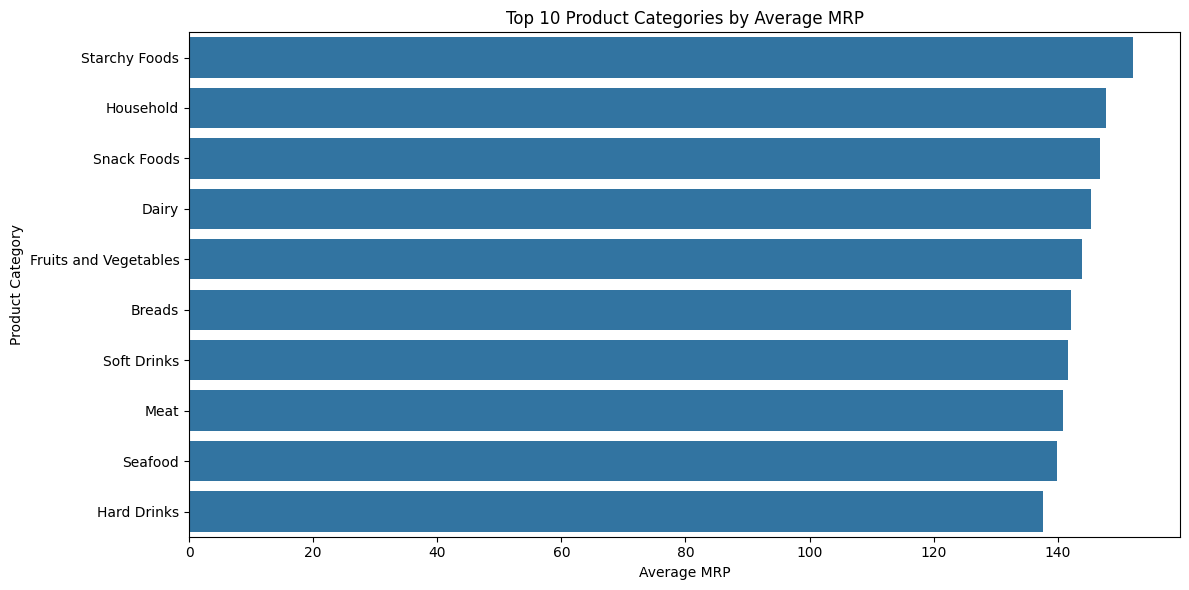

In [ ]:

top_categories = (
    df_clean.groupby('Item_Type')['Item_MRP']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title('Top 10 Product Categories by Average MRP')
plt.xlabel('Average MRP')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()


***STEP 18: Outlet Analysis***

In [ ]:

outlet_analysis = (
    df_clean.groupby('Outlet_Identifier')
    .agg(
        Product_Records=('Item_Identifier', 'count'),
        Unique_Products=('Item_Identifier', 'nunique'),
        Average_MRP=('Item_MRP', 'mean'),
        Average_Visibility=('Item_Visibility', 'mean'),
        Outlet_Year=('Outlet_Establishment_Year', 'first'),
        Outlet_Size=('Outlet_Size', 'first'),
        Outlet_Type=('Outlet_Type', 'first'),
        Location_Type=('Outlet_Location_Type', 'first')
    )
    .sort_values(
        by='Average_MRP',
        ascending=False
    )
)

display(outlet_analysis.round(2))


,Product_Records,Unique_Products,Average_MRP,Average_Visibility,Outlet_Year,Outlet_Size,Outlet_Type,Location_Type
Outlet_Identifier,,,,,,,,
OUT017,617,617,143.37,0.06,2007,Small,Supermarket Type1,Tier 2
OUT027,624,624,142.83,0.06,1985,Medium,Supermarket Type3,Tier 3
OUT049,620,620,142.46,0.06,1999,Medium,Supermarket Type1,Tier 1
OUT019,352,352,142.20,0.11,1985,Small,Grocery Store,Tier 1
OUT010,370,370,141.73,0.10,1998,Small,Grocery Store,Tier 3
OUT045,619,619,140.72,0.06,2002,Small,Supermarket Type1,Tier 2
OUT013,621,621,140.68,0.06,1987,High,Supermarket Type1,Tier 3
OUT018,618,618,139.98,0.06,2009,Medium,Supermarket Type2,Tier 3
OUT046,620,620,138.97,0.06,1997,Small,Supermarket Type1,Tier 1


***STEP 19: Outlet Type Analysis***

In [ ]:

outlet_type_analysis = (
    df_clean.groupby('Outlet_Type')
    .agg(
        Product_Records=('Item_Identifier', 'count'),
        Unique_Products=('Item_Identifier', 'nunique'),
        Average_MRP=('Item_MRP', 'mean'),
        Average_Visibility=('Item_Visibility', 'mean'),
        Number_of_Outlets=('Outlet_Identifier', 'nunique')
    )
    .sort_values(
        by='Average_MRP',
        ascending=False
    )
)

display(outlet_type_analysis.round(2))


,Product_Records,Unique_Products,Average_MRP,Average_Visibility,Number_of_Outlets
Outlet_Type,,,,,
Supermarket Type3,624,624,142.83,0.06,1
Grocery Store,722,642,141.96,0.10,2
Supermarket Type1,3717,1488,140.71,0.06,6
Supermarket Type2,618,618,139.98,0.06,1


***STEP 20: Outlet Location Analysis***

In [ ]:

location_analysis = (
    df_clean.groupby('Outlet_Location_Type')
    .agg(
        Product_Records=('Item_Identifier', 'count'),
        Average_MRP=('Item_MRP', 'mean'),
        Average_Visibility=('Item_Visibility', 'mean'),
        Unique_Outlets=('Outlet_Identifier', 'nunique')
    )
)

display(location_analysis.round(2))


,Product_Records,Average_MRP,Average_Visibility,Unique_Outlets
Outlet_Location_Type,,,,
Tier 1,1592,141.04,0.07,3
Tier 2,1856,140.72,0.06,3
Tier 3,2233,141.26,0.07,4


***STEP 21: Top 10 Products by MRP***

In [ ]:

top_products = (
    df_clean.sort_values(
        by='Item_MRP',
        ascending=False
    )[
        ['Item_Identifier', 'Item_Type',
         'Item_Fat_Content', 'Item_MRP',
         'Outlet_Identifier']
    ]
    .head(10)
)

display(top_products)


,Item_Identifier,Item_Type,Item_Fat_Content,Item_MRP,Outlet_Identifier
3380,FDR25,Canned,Regular,266.5884,OUT035
3796,FDR25,Canned,Regular,266.4884,OUT049
2883,NCM05,Health and Hygiene,Low Fat,266.3226,OUT018
4990,FDY14,Dairy,Low Fat,266.2226,OUT010
4910,FDS13,Canned,Low Fat,266.0884,OUT049
4004,FDY14,Dairy,Low Fat,265.3226,OUT017
3835,FDI15,Dairy,Low Fat,265.0884,OUT045
5571,FDI15,Dairy,Low Fat,265.0884,OUT010
1396,FDK51,Dairy,Low Fat,265.0884,OUT045
5620,FDB15,Dairy,Low Fat,265.0568,OUT045


***STEP 22: Item Visibility Analysis***

In [ ]:

visibility_analysis = (
    df_clean.groupby('Item_Type')
    .agg(
        Average_Visibility=('Item_Visibility', 'mean'),
        Maximum_Visibility=('Item_Visibility', 'max'),
        Minimum_Visibility=('Item_Visibility', 'min')
    )
    .sort_values(
        by='Average_Visibility',
        ascending=False
    )
)

display(visibility_analysis.round(4))


,Average_Visibility,Maximum_Visibility,Minimum_Visibility
Item_Type,,,
Breakfast,0.0777,0.2395,0.0000
Breads,0.0746,0.2945,0.0000
Dairy,0.0702,0.2913,0.0000
Frozen Foods,0.0699,0.2820,0.0000
Fruits and Vegetables,0.0687,0.3001,0.0000
Snack Foods,0.0679,0.3053,0.0000
Canned,0.0674,0.3139,0.0000
Soft Drinks,0.0674,0.2930,0.0000
Starchy Foods,0.0670,0.2493,0.0000


***STEP 23: Level 3 Report Export***

In [ ]:

category_analysis.to_csv('Level_3_Category_Analysis.csv')

outlet_analysis.to_csv('Level_3_Outlet_Analysis.csv')

outlet_type_analysis.to_csv('Level_3_Outlet_Type_Analysis.csv')

location_analysis.to_csv('Level_3_Location_Analysis.csv')

top_products.to_csv(
    'Level_3_Top_Products_by_MRP.csv',
    index=False
)

print("Level 3 Analysis Reports Saved!")


Level 3 Analysis Reports Saved!


***PART 5 — LEVEL 4: DATA VISUALIZATION***

***STEP 24: Product Category Distribution***

In [ ]:

category_count = (
    df_clean['Item_Type']
    .value_counts()
    .reset_index()
)

category_count.columns = [
    'Item_Type',
    'Product_Records'
]

fig = px.bar(
    category_count,
    x='Item_Type',
    y='Product_Records',
    title='Product Distribution by Category',
    color='Product_Records',
    text_auto=True
)

fig.update_layout(
    xaxis_tickangle=-45,
    template='plotly_white'
)

fig.show()


***STEP 25: Average MRP by Category***

In [ ]:

fig = px.bar(
    category_analysis.reset_index(),
    x='Item_Type',
    y='Average_MRP',
    color='Average_MRP',
    title='Average Product MRP by Category',
    text_auto='.2f'
)

fig.update_layout(
    template='plotly_white',
    xaxis_tickangle=-45
)

fig.show()


***STEP 26: Outlet Type Comparison***

In [ ]:

fig = px.bar(
    outlet_type_analysis.reset_index(),
    x='Outlet_Type',
    y='Product_Records',
    color='Average_MRP',
    title='Product Records Across Outlet Types',
    text_auto=True
)

fig.update_layout(
    template='plotly_white',
    xaxis_tickangle=-30
)

fig.show()


***STEP 27: Outlet Location Distribution***

In [ ]:

location_counts = (
    df_clean['Outlet_Location_Type']
    .value_counts()
    .reset_index()
)

location_counts.columns = [
    'Location_Type',
    'Count'
]

fig = px.pie(
    location_counts,
    names='Location_Type',
    values='Count',
    title='Outlet Location Distribution',
    hole=0.4
)

fig.show()


***STEP 28: Fat Content Distribution***

In [ ]:

fat_counts = (
    df_clean['Item_Fat_Content']
    .value_counts()
    .reset_index()
)

fat_counts.columns = [
    'Fat_Content',
    'Count'
]

fig = px.pie(
    fat_counts,
    names='Fat_Content',
    values='Count',
    title='Product Fat Content Distribution',
    hole=0.4
)

fig.show()


***STEP 29: Item MRP Distribution***

In [ ]:

fig = px.histogram(
    df_clean,
    x='Item_MRP',
    nbins=40,
    title='Distribution of Product MRP',
    color_discrete_sequence=['#F59E0B']
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Item MRP',
    yaxis_title='Frequency'
)

fig.show()


***STEP 30: Item Visibility vs MRP***

In [ ]:

fig = px.scatter(
    df_clean,
    x='Item_Visibility',
    y='Item_MRP',
    color='Item_Type',
    title='Item Visibility vs MRP',
    hover_data=['Item_Identifier', 'Outlet_Identifier']
)

fig.update_layout(
    template='plotly_white'
)

fig.show()


***STEP 31: Outlet Establishment Year Analysis***

In [ ]:

year_analysis = (
    df_clean.groupby('Outlet_Establishment_Year')
    .agg(
        Product_Records=('Item_Identifier', 'count'),
        Average_MRP=('Item_MRP', 'mean')
    )
    .reset_index()
    .sort_values('Outlet_Establishment_Year')
)

fig = px.line(
    year_analysis,
    x='Outlet_Establishment_Year',
    y='Product_Records',
    markers=True,
    title='Product Records by Outlet Establishment Year'
)

fig.update_layout(
    template='plotly_white'
)

fig.show()


***STEP 32: KPI Metrics***

In [ ]:

kpis = {
    'Total Records': len(df_clean),

    'Unique Products':
        df_clean['Item_Identifier'].nunique(),

    'Total Outlets':
        df_clean['Outlet_Identifier'].nunique(),

    'Average MRP':
        round(df_clean['Item_MRP'].mean(), 2),

    'Average Visibility':
        round(df_clean['Item_Visibility'].mean(), 4),

    'Product Categories':
        df_clean['Item_Type'].nunique()
}

for key, value in kpis.items():
    print(f"{key}: {value}")


Total Records: 5681
Unique Products: 1543
Total Outlets: 10
Average MRP: 141.02
Average Visibility: 0.0657
Product Categories: 16


***PART 6 — LEVEL 5: DASHBOARD & BUSINESS INSIGHTS***

***STEP 33: Building a Streamlit App for a Dashboard***

In [ ]:

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

st.set_page_config(
    page_title="Big Mart Retail Analytics",
    page_icon="🛒",
    layout="wide"
)

st.title("🛒 Big Mart Retail Analytics Dashboard")

st.markdown(
    "### Business Analytics Internship | Sysslan IT Solutions"
)

st.caption(
    "Product, Pricing, Visibility and Outlet Analysis"
)

# Load dataset

@st.cache_data
def load_data():
    data = pd.read_csv("Big_Mart_Cleaned.csv")
    return data

df = load_data()

# Sidebar filters

st.sidebar.title("Dashboard Filters")

categories = st.sidebar.multiselect(
    "Select Product Category",
    options=sorted(df["Item_Type"].unique()),
    default=sorted(df["Item_Type"].unique())
)

outlets = st.sidebar.multiselect(
    "Select Outlet",
    options=sorted(df["Outlet_Identifier"].unique()),
    default=sorted(df["Outlet_Identifier"].unique())
)

outlet_types = st.sidebar.multiselect(
    "Select Outlet Type",
    options=sorted(df["Outlet_Type"].unique()),
    default=sorted(df["Outlet_Type"].unique())
)

fat_types = st.sidebar.multiselect(
    "Select Fat Content",
    options=sorted(df["Item_Fat_Content"].unique()),
    default=sorted(df["Item_Fat_Content"].unique())
)

min_mrp = float(df["Item_MRP"].min())
max_mrp = float(df["Item_MRP"].max())

mrp_range = st.sidebar.slider(
    "Select MRP Range",
    min_value=min_mrp,
    max_value=max_mrp,
    value=(min_mrp, max_mrp)
)

# Apply filters

filtered_df = df[
    (df["Item_Type"].isin(categories)) &
    (df["Outlet_Identifier"].isin(outlets)) &
    (df["Outlet_Type"].isin(outlet_types)) &
    (df["Item_Fat_Content"].isin(fat_types)) &
    (df["Item_MRP"].between(mrp_range[0], mrp_range[1]))
].copy()

if filtered_df.empty:
    st.warning("No records found. Please change your filters.")
    st.stop()

# KPI section

st.subheader("📊 Key Performance Indicators")

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Total Records",
    f"{len(filtered_df):,}"
)

c2.metric(
    "Unique Products",
    f"{filtered_df['Item_Identifier'].nunique():,}"
)

c3.metric(
    "Total Outlets",
    f"{filtered_df['Outlet_Identifier'].nunique():,}"
)

c4.metric(
    "Average MRP",
    f"₹{filtered_df['Item_MRP'].mean():,.2f}"
)

c5, c6, c7, c8 = st.columns(4)

c5.metric(
    "Average Visibility",
    f"{filtered_df['Item_Visibility'].mean():.4f}"
)

c6.metric(
    "Categories",
    filtered_df["Item_Type"].nunique()
)

c7.metric(
    "Average Weight",
    f"{filtered_df['Item_Weight'].mean():.2f}"
)

c8.metric(
    "Median MRP",
    f"₹{filtered_df['Item_MRP'].median():,.2f}"
)

st.divider()

# Category analysis

st.subheader("📦 Product Category Analysis")

category_data = (
    filtered_df.groupby("Item_Type")
    .agg(
        Product_Records=("Item_Identifier", "count"),
        Average_MRP=("Item_MRP", "mean")
    )
    .reset_index()
)

col1, col2 = st.columns(2)

with col1:
    fig1 = px.bar(
        category_data.sort_values(
            "Product_Records", ascending=False
        ),
        x="Item_Type",
        y="Product_Records",
        title="Product Records by Category",
        color="Product_Records"
    )
    fig1.update_layout(
        xaxis_tickangle=-45,
        template="plotly_white"
    )
    st.plotly_chart(fig1, use_container_width=True)

with col2:
    fig2 = px.bar(
        category_data.sort_values(
            "Average_MRP", ascending=False
        ),
        x="Item_Type",
        y="Average_MRP",
        title="Average MRP by Category",
        color="Average_MRP"
    )
    fig2.update_layout(
        xaxis_tickangle=-45,
        template="plotly_white"
    )
    st.plotly_chart(fig2, use_container_width=True)

# Outlet analysis

st.subheader("🏬 Outlet Performance Profile")

outlet_data = (
    filtered_df.groupby("Outlet_Type")
    .agg(
        Product_Records=("Item_Identifier", "count"),
        Average_MRP=("Item_MRP", "mean")
    )
    .reset_index()
)

col3, col4 = st.columns(2)

with col3:
    fig3 = px.bar(
        outlet_data,
        x="Outlet_Type",
        y="Product_Records",
        color="Outlet_Type",
        title="Product Records by Outlet Type"
    )
    fig3.update_layout(template="plotly_white")
    st.plotly_chart(fig3, use_container_width=True)

with col4:
    location_data = (
        filtered_df["Outlet_Location_Type"]
        .value_counts()
        .reset_index()
    )
    location_data.columns = ["Location", "Count"]

    fig4 = px.pie(
        location_data,
        names="Location",
        values="Count",
        hole=0.4,
        title="Outlet Location Distribution"
    )
    st.plotly_chart(fig4, use_container_width=True)

# Fat content analysis

st.subheader("🥗 Product Fat Content Analysis")

fat_data = (
    filtered_df["Item_Fat_Content"]
    .value_counts()
    .reset_index()
)
fat_data.columns = ["Fat_Content", "Count"]

fig5 = px.pie(
    fat_data,
    names="Fat_Content",
    values="Count",
    hole=0.4,
    title="Fat Content Distribution"
)

st.plotly_chart(fig5, use_container_width=True)

# Visibility analysis

st.subheader("👁️ Product Visibility Analysis")

fig6 = px.scatter(
    filtered_df,
    x="Item_Visibility",
    y="Item_MRP",
    color="Item_Type",
    hover_data=[
        "Item_Identifier",
        "Outlet_Identifier"
    ],
    title="Product Visibility vs MRP"
)

fig6.update_layout(template="plotly_white")

st.plotly_chart(fig6, use_container_width=True)

# MRP distribution

st.subheader("💰 Product Pricing Distribution")

fig7 = px.histogram(
    filtered_df,
    x="Item_MRP",
    nbins=35,
    title="MRP Distribution",
    color_discrete_sequence=["#F59E0B"]
)

st.plotly_chart(fig7, use_container_width=True)

# Top products by MRP

st.subheader("🏆 Top 10 Products by MRP")

top_products = (
    filtered_df.sort_values(
        "Item_MRP", ascending=False
    )
    [[
        "Item_Identifier",
        "Item_Type",
        "Item_MRP",
        "Outlet_Identifier"
    ]]
    .head(10)
)

st.dataframe(
    top_products,
    use_container_width=True,
    hide_index=True
)

# Business insights

st.subheader("💡 Business Insights")

top_category = (
    filtered_df["Item_Type"].value_counts().idxmax()
)

highest_mrp_category = (
    category_data.sort_values(
        "Average_MRP", ascending=False
    ).iloc[0]["Item_Type"]
)

top_outlet_type = (
    filtered_df["Outlet_Type"].value_counts().idxmax()
)

st.markdown(
    f"""
    - **Most represented product category:** {top_category}
    - **Highest average MRP category:** {highest_mrp_category}
    - **Most represented outlet type:** {top_outlet_type}
    - **Average product MRP:** ₹{filtered_df['Item_MRP'].mean():.2f}
    - **Average item visibility:** {filtered_df['Item_Visibility'].mean():.4f}
    """
)

st.info(
    "Important: This dataset does not contain Item_Outlet_Sales. "
    "Therefore, the dashboard reports product pricing and outlet "
    "profiles, not actual sales revenue or sales performance."
)

# Data explorer

st.subheader("🔎 Product Data Explorer")

search = st.text_input(
    "Search by Product Identifier"
)

if search:
    search_df = filtered_df[
        filtered_df["Item_Identifier"].str.contains(
            search, case=False, na=False
        )
    ]
else:
    search_df = filtered_df

st.dataframe(
    search_df,
    use_container_width=True,
    hide_index=True
)

# Download

st.subheader("📥 Download Filtered Data")

csv = filtered_df.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download Filtered Dataset",
    data=csv,
    file_name="filtered_big_mart_data.csv",
    mime="text/csv"
)

st.success("Dashboard loaded successfully!")


Writing app.py


***STEP 34: Create a requirements file***

In [ ]:

%%writefile requirements.txt

streamlit
pandas
numpy
plotly


Writing requirements.txt


***STEP 40: Prepare the cleaned CSV for the dashboard***

In [ ]:

df_clean.to_csv(
    'Big_Mart_Cleaned.csv',
    index=False
)

print("Dashboard dataset ready!")


Dashboard dataset ready!


***STEP 41: Download three files***

In [ ]:

from google.colab import files

files.download('app.py')
files.download('requirements.txt')
files.download('Big_Mart_Cleaned.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>